In [1]:
import pandas as pd
from main import SimulationType

# TODO: rerun Walker_2018, Radjenovic_2013, Chou_2014 for alpha=0.05
dataset_names = [
    "Appenzeller-Herzog_2019", 
    "Bos_2018", 
    "Brouwer_2019", 
    "Chou_2003",
    "Chou_2004", 
    "Hall_2012", 
    "Jeyaraman_2020", 
    "Leenaars_2019", 
    "Leenaars_2020",
    "Moran_2021", 
    "Muthu_2021", 
    #"Radjenovic_2013", 
    "Smid_2020", 
    "van_de_Schoot_2018", 
    "van_der_Waal_2022", 
    "van_Dis_2020",
    #"Walker_2018", 
    "Wassenaar_2017", 
    "Wolters_2018"
                 ]
simulation_types = ["BASELINE","REORDERING","GAP_FILLING"]
alphas = [0.1]
recall_targets = [0.8]

In [2]:
import os
import pyarrow as pa
import pyarrow.dataset as ds

ROOT = "screening_results"

# text columns (title/abstract/texts) are ~93% of the bytes on disk and unused here
COLUMNS = ["incl", "sim_seen", "sim_seen_in_update", "random_sample", "p_score",
           "review_update", "sim_order", "prediction", "run_id",
           "dataset_name", "simulation_type", "alpha", "recall_target"]

SCHEMA = pa.schema([
    ("incl", pa.int8()), ("sim_seen", pa.int8()), ("sim_seen_in_update", pa.float32()),
    ("random_sample", pa.int8()), ("p_score", pa.float32()), ("review_update", pa.int16()),
    ("sim_order", pa.float32()), ("prediction", pa.float32()), ("run_id", pa.int32()),
    ("dataset_name", pa.string()), ("simulation_type", pa.string()),
    ("alpha", pa.float64()), ("recall_target", pa.float64()),
])

PARTITIONING = ds.partitioning(
    pa.schema([("dataset_name", pa.string()), ("simulation_type", pa.string()),
               ("alpha", pa.float64()), ("recall_target", pa.float64())]),
    flavor="hive")

def _is_valid_parquet(path):
    """Non-empty and terminated by the PAR1 footer magic."""
    try:
        with open(path, "rb") as fh:
            if fh.seek(0, 2) < 8:          # too small to hold header+footer
                return False
            fh.seek(-4, 2)
            return fh.read(4) == b"PAR1"
    except OSError:
        return False


def _subdirs(path, key, wanted, as_float):
    out = []
    if not os.path.isdir(path):
        return out
    for e in os.scandir(path):
        if not e.is_dir() or not e.name.startswith(key + "="):
            continue
        val = e.name.split("=", 1)[1]
        val = float(val) if as_float else val
        if wanted is None or any(abs(val - w) < 1e-9 if as_float else val == w
                                 for w in wanted):
            out.append(e.path)
    return out


def partition_files(dataset_names=None, simulation_types=None, alphas=None,
                    recall_targets=None, root=ROOT):
    """Fully-partitioned, non-empty parquet files matching the selection."""
    files, skipped = [], 0
    for p1 in _subdirs(root, "dataset_name", dataset_names, False):
        for p2 in _subdirs(p1, "simulation_type", simulation_types, False):
            for p3 in _subdirs(p2, "alpha", alphas, True):
                for p4 in _subdirs(p3, "recall_target", recall_targets, True):
                    for e in os.scandir(p4):
                        if not e.name.endswith(".parquet"):
                            continue
                        if not _is_valid_parquet(e.path):
                            skipped += 1
                            continue
                        files.append(e.path)
    return files, skipped


def load_results(dataset_names=None, simulation_types=None, alphas=None,
                 recall_targets=None, columns=COLUMNS, root=ROOT):
    files, skipped = partition_files(dataset_names, simulation_types, alphas,
                                     recall_targets, root)
    print(f"{len(files)} parquet files, {skipped} empty files skipped")
    if not files:
        raise FileNotFoundError("no matching partitions")

    dataset = ds.dataset(files, format="parquet", partitioning=PARTITIONING,
                         partition_base_dir=root)
    target = pa.schema([SCHEMA.field(n) for n in columns])
    # cast batch by batch so the full int64/float64 table never exists at once
    scanner = ds.Scanner.from_dataset(dataset, columns=columns, batch_size=1 << 17)
    table = pa.Table.from_batches(
        [b.cast(target) for b in scanner.to_batches() if b.num_rows], schema=target)
    for name in ("dataset_name", "simulation_type"):
        i = table.schema.get_field_index(name)
        if i >= 0:
            table = table.set_column(i, name, table.column(name).dictionary_encode())
    print("rows", table.num_rows, "arrow GB", round(table.nbytes / 1e9, 2))
    return table.to_pandas(self_destruct=True, split_blocks=True)


df = load_results(dataset_names, simulation_types, alphas, recall_targets)
# TODO: are empty files cause by missed simulation combination or something else?

3699 parquet files, 195 empty files skipped
rows 25880142 arrow GB 1.28


In [3]:
print(df.shape[0])
display(df)

25880142


,incl,sim_seen,sim_seen_in_update,random_sample,p_score,review_update,sim_order,prediction,run_id,dataset_name,simulation_type,alpha,recall_target
0,0,0,NaN,0,NaN,0,0.0,0.017029,87,Leenaars_2020,REORDERING,0.1,0.8
1,0,0,NaN,0,NaN,0,0.0,0.009176,87,Leenaars_2020,REORDERING,0.1,0.8
2,0,1,0.0,0,NaN,0,1419.0,0.034233,87,Leenaars_2020,REORDERING,0.1,0.8
3,0,1,0.0,1,NaN,0,229.0,NaN,87,Leenaars_2020,REORDERING,0.1,0.8
4,0,0,NaN,0,NaN,0,0.0,0.010351,87,Leenaars_2020,REORDERING,0.1,0.8
...,...,...,...,...,...,...,...,...,...,...,...,...,...
25880137,0,1,2.0,0,NaN,2,2858.0,0.004847,1,Hall_2012,BASELINE,0.1,0.8
25880138,0,0,NaN,0,NaN,2,NaN,0.001143,1,Hall_2012,BASELINE,0.1,0.8
25880139,0,0,NaN,0,NaN,2,NaN,0.001510,1,Hall_2012,BASELINE,0.1,0.8
25880140,0,0,NaN,0,NaN,2,NaN,0.002095,1,Hall_2012,BASELINE,0.1,0.8


In [4]:
df.groupby("simulation_type").size()

/tmp/ipykernel_37823/3612871036.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby("simulation_type").size()


simulation_type
REORDERING     8660734
GAP_FILLING    8556766
BASELINE       8662642
dtype: int64

In [5]:
SIM = "BASELINE"          # seen-counts depend on the strategy, so fix one
UPDATE = df["review_update"].max()

snap = df[(df["simulation_type"] == SIM)] #& (df["review_update"] == UPDATE)]

rows = []
for (dataset, alpha, recall_target), g in snap.groupby(["dataset_name", "alpha", "recall_target"], observed=True):
    for run_id, r in g.groupby("run_id", observed=True):
        rows.append({
            "dataset": dataset,
            "run_id": run_id,
            "total records": len(r),
            "records seen": int((r["sim_seen"] == 1).sum()),
            "total includes": int(r["incl"].sum()),
            "includes seen": int(((r["sim_seen"] == 1) & (r["incl"] == 1)).sum()),
            "recall_target": recall_target,
        })

overview = pd.DataFrame(rows).sort_values("dataset").reset_index(drop=True)
overview["% records seen"] = (100 * overview["records seen"] / overview["total records"]).round(1)
overview["% includes seen"] = (100 * overview["includes seen"] / overview["total includes"]).round(1)
print(overview.to_string(index=False))

# Hall_2012 have some issues with simulation sometimes
# Radjenovic_2013, Wolters_2018 have some issues with simulation all the time
# all the other ones seem fine
# quick fix: skip these combinations for plots
# TODO: set up DVC for simulation results, figure out what is going on
# TODO: rerun Radjenovic and Walker 


                dataset  run_id  total records  records seen  total includes  includes seen  recall_target  % records seen  % includes seen
Appenzeller-Herzog_2019      71           2873          2158              26             26            0.8            75.1            100.0
Appenzeller-Herzog_2019       5           2873          2158              26             26            0.8            75.1            100.0
Appenzeller-Herzog_2019       3           2873          2158              26             26            0.8            75.1            100.0
Appenzeller-Herzog_2019       1           2873          2158              26             26            0.8            75.1            100.0
Appenzeller-Herzog_2019      49           2873          2158              26             26            0.8            75.1            100.0
Appenzeller-Herzog_2019      50           2873          2158              26             26            0.8            75.1            100.0
Appenzeller-Herzog_2

#TODO:  (1) check for each dataset, run_id and sim_type that the total number of records in the dataset matches the original data, print combinations where that's not the case
and (2) identify in main.py where this is happening and why and fix

Nr 	Dataset 	Topic(s) 	Records 	Included 	%
1 	Appenzeller-Herzog_2019 	Medicine 	2873 	26 	0.9
2 	Bos_2018 	Medicine 	4878 	10 	0.2
3 	Brouwer_2019 	Psychology, Medicine 	38114 	62 	0.2
4 	Chou_2003 	Medicine 	1908 	15 	0.8
5 	Chou_2004 	Medicine 	1630 	9 	0.6 in min run_id
7 	Hall_2012 	Computer science 	8793 	104 	1.2 in max run_id
8 	Jeyaraman_2020 	Medicine 	1175 	96 	8.2
9 	Leenaars_2019 	Psychology, Chemistry, Medicine 	5812 	17 	0.3
10 	Leenaars_2020 	Medicine 	7216 	583 	8.1
13 	Moran_2021 	Biology, Medicine 	5214 	111 	2.1
14 	Muthu_2021 	Medicine 	2719 	336 	12.4
17 	Radjenovic_2013 	Computer science 	5935 	48 	0.8 in max run_id, in min run_id
19 	Smid_2020 	Computer science, Mathematics 	2627 	27 	1
20 	van_de_Schoot_2018 	Psychology, Medicine 	4544 	38 	0.8
22 	van_der_Waal_2022 	Medicine 	1970 	33 	1.7
23 	van_Dis_2020 	Psychology, Medicine 	9128 	72 	0.8
24 	Walker_2018 	Biology, Medicine 	48375 	762 	1.6
25 	Wassenaar_2017 	Medicine, Biology, Chemistry 	7668 	111 	1.4
26 	Wolters_2018 	Medicine 	4280 	19 	0.4 in max run_id, in min run_id

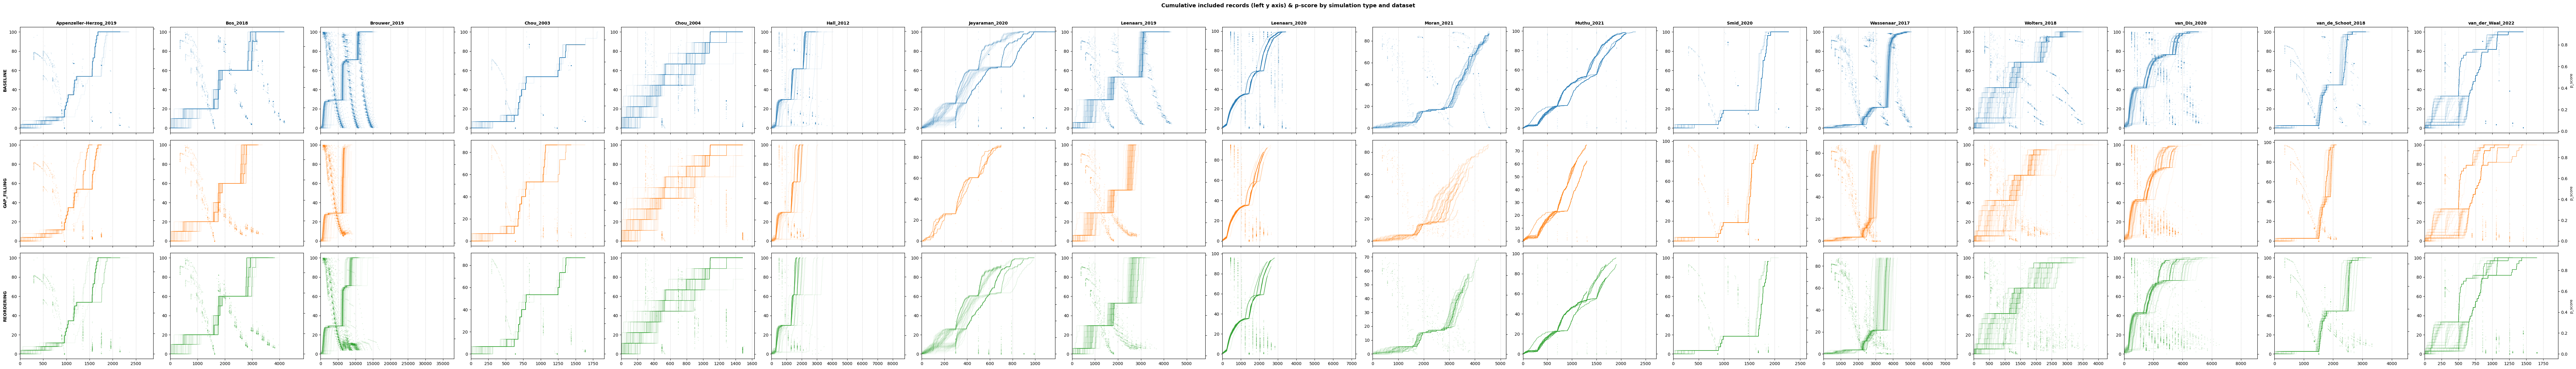

In [ ]:
# TODO: fix x axis limit - when we filter by alpha and recall target, it's fine
# TODO: check the colouring of the simulation types

import numpy as np
from IPython.display import display, Latex
import matplotlib.pyplot as plt

# Get unique values
datasets = sorted(df["dataset_name"].unique())
sim_types = sorted(df["simulation_type"].unique()) 

n_cols, n_rows = len(datasets), len(sim_types)

fig, axes = plt.subplots(
    n_rows, n_cols,
    figsize=(5 * n_cols, 4 * n_rows),
    sharex="col",
    squeeze=False
)

axes2 = np.empty_like(axes, dtype=object)
for r in range(n_rows):
    for c in range(n_cols):
        axes2[r, c] = axes[r, c].twinx()

# One fixed colour per simulation type (reuse this dict in other plots)
sim_color = {sim: f"C{i}" for i, sim in enumerate(sim_types)}

for c, dataset in enumerate(datasets):
    dgroup = df[df["dataset_name"] == dataset]

    for r, sim_type in enumerate(sim_types):
        ax, ax2  = axes[r, c], axes2[r, c]

        sgroup = dgroup[dgroup["simulation_type"] == sim_type]
        if sgroup.empty:
            ax.set_visible(False)
            ax2.set_visible(False)
            continue
        
        color = sim_color[sim_type]
        line_alpha = max(0.1, min(0.8, 8 / sgroup["run_id"].nunique()))
        x_max = 0

        for run_id, rgroup in sgroup.groupby("run_id", sort=True):
            rgroup = rgroup.sort_values("sim_order").reset_index(drop=True) # do we need to reset index here?
            if rgroup.empty:
                continue
            #max_len = max(max_len, rgroup.shape[0])
        

            ax.plot(rgroup["sim_order"], 
                    100 * rgroup["incl"].cumsum() / rgroup["incl"].sum(),
                    color=color, alpha=line_alpha, linewidth=0.8)
            ax2.scatter(rgroup["sim_order"], rgroup["p_score"],
                        color=color, alpha=0.15, s=4, linewidths=0)

        ax.set_xlim(0, rgroup.shape[0])

        # Add vertical grid lines
        ax.xaxis.grid(True, linestyle="--", linewidth=0.6, alpha=0.7, zorder=0)
        ax.set_axisbelow(True)

        # Row labels (simulation type) on the leftmost column only
        if c == 0:
            ax.set_ylabel(sim_type, fontsize=10, fontweight="bold")

        # Column labels (dataset name) on the top row only
        if r == 0:
            ax.set_title(dataset, fontsize=10, fontweight="bold")

        # Right y-axis label only on the rightmost column
        if c == n_cols - 1:
            ax2.set_ylabel("p_score", fontsize=9)
        else:
            ax2.set_yticklabels([])
            #display(Latex(f"$p={min(y):.2f}$ for $H_0$ that recall of {t['tau_target']} has not been achieved"))


fig.suptitle(f"Cumulative included records (left y axis) & p-score by simulation type and dataset for alpha={alphas[0]} and recall_target={recall_targets[0]}",
             fontsize=13, fontweight="bold", y=1.01)
plt.tight_layout()
plt.show()

In [ ]:
# TODO: make sure the colour and sim_type are correct, it looks like REORDERING underperforms compared to BASELINE in Brouwer_2018 
# TODO: find ways to aggregate or present this data better 
# TODO: add a true recall x work savings graph

from matplotlib.lines import Line2D

for (dataset, alpha, recall_target), dgroup in df.groupby(["dataset_name","alpha","recall_target"]):
    fig, ax = plt.subplots()
    ax2 = ax.twinx()
    max_len = 0

    for i, (sim_type, sgroup) in enumerate(dgroup.groupby("simulation_type")):
        color = f"C{i}"
        line_alpha = max(0.1, min(0.8, 8 / sgroup["run_id"].nunique()))

        for run_id, rgroup in sgroup.groupby("run_id", sort=True):
            rgroup = (rgroup.sort_values("sim_order")
                            .reset_index(drop=True))
            if rgroup.empty:
                continue
            max_len = max(max_len, rgroup.shape[0])
        
            ax.plot(rgroup["sim_order"], rgroup["incl"].cumsum(), 
                    color=color, alpha=line_alpha, linewidth=0.8)
            ax2.scatter(rgroup["sim_order"], rgroup["p_score"], 
                        color=color, alpha=0.15, s=4, linewidths=0)
    ax.set_xlim(0, max_len)
    ax.set_xlabel("sim_order")
    ax.set_ylabel("cumulative included records")
    ax2.set_ylabel("p_score")
    ax.set_title(f"{dataset} — recall_target={recall_target}, alpha={alpha}",
                fontsize=11, fontweight="bold")

    # one legend entry per simulation type, not per run
    sims = sorted(dgroup["simulation_type"].unique())
    ax.legend(handles=[Line2D([], [], color=f"C{i}", label=s)
                    for i, s in enumerate(sims)], fontsize=8)
    plt.tight_layout()
    plt.show()


In [ ]:
histograms = {}
results_table = []
review_updates = [0, 1, 2]
for dataset, dgroup in df.groupby("dataset_name"):
    histograms[dataset] = {}
    datasets.append(dataset)
    for sim_type, sgroup in dgroup.groupby("simulation_type"):
        histograms[dataset][sim_type] = {}
        for alpha, agroup in sgroup.groupby("alpha"):
            histograms[dataset][sim_type][alpha] = {}
            for recall_target, tgroup in agroup.groupby("recall_target"):
                histograms[dataset][sim_type][alpha][recall_target] = {}
                for review_update in review_updates:
                    savings_list = []
                    total_savings_list = []
                    recall_list = []
                    total_recall_list = []
                    histograms[dataset][sim_type][alpha][recall_target][review_update] = {}

                    for run_id, rgroup in tgroup.groupby("run_id"):
                        update_rgroup = rgroup[rgroup["review_update"] <= review_update]

                        if update_rgroup.shape[0] == 0:
                            continue

                        #n_seen = update_rgroup["sim_seen"].sum() # len of uodate group where sim_seem_in_update == "review_update" (check they are the same type)
                        n_seen = update_rgroup[update_rgroup["sim_seen_in_update"] == int(review_update)].shape[0]
                        savings = 1 - n_seen / update_rgroup.shape[0]
                        # 1 - the number of documents seen in this update

                        total_seen_so_far = update_rgroup[update_rgroup["review_update"]<=int(review_update)]["sim_seen"].sum()
                        total_records_so_far = update_rgroup[update_rgroup["review_update"]<=int(review_update)].shape[0]
                        total_savings = 1 - total_seen_so_far / total_records_so_far

                        incl_total = update_rgroup["incl"].sum() #sum of incl where sim_seem_in_update == "review_update"
                        if incl_total == 0:
                            continue

                        #recall = update_rgroup[update_rgroup["sim_seen"] == 1]["incl"].sum() / incl_total  #sum of incl where sim_seem_in_update == "review_update"
                        #total_recall = update_rgroup[update_rgroup["review_update"] <= int(review_update)]["incl"].sum() / incl_total
                        total_recall = update_rgroup[(update_rgroup["review_update"] <= int(review_update)) & (update_rgroup["sim_seen"] == 1)]["incl"].sum() / incl_total

                        total_savings_list.append(total_savings)
                        savings_list.append(savings)
                        total_recall_list.append(total_recall)
                        #recall_list.append(recall)

                    if len(savings_list) == 0:
                        continue

                    histograms[dataset][sim_type][alpha][recall_target][review_update]["savings"] = savings_list
                    # TODO: histograms[dataset][sim_type][alpha][recall_target][review_update]["recall"] = recall_list
                    histograms[dataset][sim_type][alpha][recall_target][review_update]["total_savings"] = total_savings_list
                    histograms[dataset][sim_type][alpha][recall_target][review_update]["total_recall"] = total_recall_list

                    results_table.append({
                        "dataset": dataset,
                        "simulation_type": sim_type,
                        "alpha": alpha,
                        "recall_target": recall_target,
                        "review_update": review_update,
                        "sim_seen_in_update": n_seen,
                        "incl_seen_in_update": update_rgroup[update_rgroup["sim_seen_in_update"] == int(review_update)]["incl"].sum(),
                        "incl_in_update": incl_total,
                        "savings": sum(savings_list) / len(savings_list),
                        "total_savings": sum(total_savings_list) / len(total_savings_list),
                        "total_recall": sum(total_recall_list) / len(total_recall_list),
                        # TODO: "recall": sum(recall_list) / len(recall_list),
                        "n_runs": len(savings_list)
                    })

pd.DataFrame(results_table)

In [ ]:
import numpy as np

FINAL_UPDATE = max(review_updates)   # 2

summary_rows = []
for dataset in histograms:
    for sim in sim_types:
        for alpha in histograms[dataset][sim]:
            for recall_target in histograms[dataset][sim][alpha]:
                entry = histograms[dataset][sim][alpha][recall_target].get(FINAL_UPDATE)
                if not entry:
                    continue
                recall = np.asarray(entry["total_recall"])
                savings = np.asarray(entry["total_savings"])
                summary_rows.append({
                    "dataset": dataset,
                    "alpha": alpha,
                    "recall_target": recall_target,
                    "simulation_type": sim,
                    "true recall": recall.mean(),
                    "recall sd": recall.std(ddof=1) if recall.size > 1 else np.nan,
                    "total work savings": savings.mean(),
                    "savings sd": savings.std(ddof=1) if savings.size > 1 else np.nan,
                    "n_runs": recall.size,
                })

summary = pd.DataFrame(summary_rows)

for (dataset, alpha, recall_target), g in summary.groupby(
        ["dataset", "alpha", "recall_target"], observed=True):
    tbl = (g.set_index("simulation_type")
             .reindex(sim_types)
             .loc[:, ["true recall", "recall sd", "total work savings",
                      "savings sd", "n_runs"]])
    print(f"\n{dataset} | alpha={alpha} | recall_target={recall_target}")
    print(tbl.to_string(float_format=lambda v: f"{v:.3f}"))


In [ ]:
def pm(mean, sd):
    return f"{mean:.3f}" if pd.isna(sd) else rf"{mean:.3f} $\pm$ {sd:.3f}"

for (alpha, recall_target), g in summary.groupby(["alpha", "recall_target"], observed=True):
    tex_df = pd.DataFrame({
        "dataset": g["dataset"],
        "simulation": g["simulation_type"],
        "True recall": [pm(m, s) for m, s in zip(g["true recall"], g["recall sd"])],
        "Total work savings": [pm(m, s) for m, s in zip(g["total work savings"], g["savings sd"])],
        "$n$": g["n_runs"],
    }).set_index(["dataset", "simulation"]).sort_index()

    caption = (rf"Mean $\pm$ SD across runs after review update {FINAL_UPDATE} "
               rf"($\alpha={alpha}$, recall target ${recall_target}$).")
    tex = tex_df.to_latex(
        escape=False,                 # keeps the $\pm$ maths
        multirow=True,                # one dataset label spanning its rows
        column_format="llrrr",
        caption=caption,
        label=f"tab:results-a{alpha}-r{recall_target}",
        position="htbp",
    )
    path = f"results_alpha{alpha}_recall{recall_target}.tex"
    with open(path, "w") as fh:
        fh.write(tex)
    print(path)
    print(tex)

In [ ]:

for dataset in dataset_names:
    for alpha in alphas:
        for recall_target in recall_targets:
            fig, axs = plt.subplots(1,3, sharey=True, figsize=(12,4))
            for review_update in review_updates:
                ax = axs[review_update]
                ax.set_title(f"{dataset} - {alpha} - {review_update}")
                y = [
                    histograms[dataset][sim][alpha][recall_target][review_update]["total_savings"]
                    for sim in sim_types
                ]
                x = [
                    np.linspace(i+1-0.3, i+1+0.3, len(data))
                    #np.random.normal(i+1, 0.1, size=len(data))
                    for i, data in enumerate(y)
                ]
                ax.boxplot(y)
                for xx,yy in zip(x,y):
                    ax.scatter(
                        xx,yy, s=5, alpha=0.5
                    )
                ax.set_xticklabels([sim for sim in sim_types])
            axs[0].set_ylim(0.0, 1.0)
            fig.supylabel('Total work savings', fontsize=14)
            #fig.suptitle('Total work savings for different simulation types and review updates', fontsize=16, fontweight='bold')
            fig.tight_layout()
            plt.show()

# why are we getting different values for baseline review (0) in different simulation types - is it because we can see these documents in further review updates?
# because we are plotting total_savings! rather than savings inside a review update

In [ ]:

# TODO: present this together with work savings?
for dataset in dataset_names:
    for alpha in alphas:
        for recall_target in recall_targets:
            fig, axs = plt.subplots(1,3, sharey=True, figsize=(8,5))
            all_vals = []
            for review_update in review_updates:
                ax = axs[review_update]
                ax.set_title(f"{dataset} - {alpha} - {review_update}")
                y = [
                    histograms[dataset][sim][alpha][recall_target][review_update]["total_recall"]
                    for sim in sim_types
                ]
                all_vals += [v for data in y for v in data]
                x = [
                    np.linspace(i+1-0.3, i+1+0.3, len(data))
                    #np.random.normal(i+1, 0.1, size=len(data))
                    for i, data in enumerate(y)
                ]
                ax.boxplot(y)
                for xx,yy in zip(x,y):
                    ax.scatter(
                        xx,yy, s=5, alpha=0.5
                    )
                ax.set_xticklabels([sim for sim in sim_types])
            
            lo, hi = min(all_vals), max(all_vals)
            pad = 0.02 * (hi - lo) if hi > lo else 0.01
            axs[0].set_ylim(lo - pad, hi + pad)   # shared, so one call is enough
            
            fig.supylabel('Total recall', fontsize=14)
            fig.tight_layout()
            plt.show()



In [ ]:
# TODO: scatterplot of per dataset true recall x true work savings
# TODO: scatterplot of per dataset target recall plus alpha (2nd y axis) x true work savings

In [ ]:
colour_map = {
    "BASELINE": "blue",
    "REORDERING": "green",
    "GAP_FILLING": "orange",
}

for dataset in dataset_names:
    for alpha in alphas:
        for recall_target in recall_targets:
            fig, axs = plt.subplots(1, 3, sharey=True, figsize=(8, 5))
            all_vals = []
            for review_update in review_updates:
                ax = axs[review_update]
                ax.set_title(f"{dataset} - {alpha} - {review_update}")

                y = [
                    histograms[dataset][sim][alpha][recall_target][review_update]["total_recall"]
                    for sim in sim_types
                ]
                x = [
                    histograms[dataset][sim][alpha][recall_target][review_update]["total_savings"]
                    for sim in sim_types
                ]

                all_vals += [v for data in y for v in data]

                for sim, xx, yy in zip(sim_types, x, y):
                    ax.scatter(
                        xx, yy, s=5, alpha=0.25,
                        color=color_map[sim],
                        label=sim,
                    )

                ax.set_xlabel("Work savings")
                ax.legend(fontsize=8)

            lo, hi = min(all_vals), max(all_vals)
            pad = 0.02 * (hi - lo) if hi > lo else 0.01
            axs[0].set_ylim(lo - pad, hi + pad)  # shared, so one call is enough

            fig.supylabel("True total recall", fontsize=14)
            fig.tight_layout()
            plt.show()

In [ ]:
markers = {rt: m for rt, m in zip(sorted(summary["recall_target"].unique()), ["o", "s", "^", "D"])}

metrics = [("total work savings", "savings sd", "Total work savings"),
           ("true recall",        "recall sd",  "True recall")]

order = sorted(summary["dataset"].unique())
ypos = {d: i for i, d in enumerate(order)}

fig, axs = plt.subplots(1, 2, sharey=True, figsize=(10, 0.45 * len(order) + 2))

for ax, (col, sd_col, label) in zip(axs, metrics):
    for k, sim in enumerate(sim_types):
        g = summary[summary["simulation_type"] == sim]
        for rt, grt in g.groupby("recall_target", observed=True):
            off = 0.22 * (k - (len(sim_types) - 1) / 2)
            ax.errorbar(
                grt[col], [ypos[d] + off for d in grt["dataset"]],
                xerr=grt[sd_col], fmt=markers[rt], ms=4, lw=1, capsize=2,
                color=colour_map[sim],
                label=f"{sim} (target {rt})",
            )
    ax.set_xlabel(label)
    ax.grid(axis="x", ls="--", lw=0.5, alpha=0.6)
    ax.set_axisbelow(True)

axs[0].set_yticks(range(len(order)))
axs[0].set_yticklabels(order, fontsize=9)
axs[0].invert_yaxis()
axs[1].axvline(recall_targets[0], color="grey", ls=":", lw=1)  # nominal target

handles, labels = axs[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=len(sim_types),
           fontsize=8, frameon=False, bbox_to_anchor=(0.5, -0.02))
fig.suptitle(f"After review update {FINAL_UPDATE} (mean ± SD across runs)", fontsize=11)
fig.tight_layout()
plt.show()

# wide table: one row per dataset, one column block per (recall_target, sim_type)
wide = (summary
        .assign(**{"work savings": lambda d: d.apply(lambda r: f"{r['total work savings']:.3f} ± {r['savings sd']:.3f}", axis=1),
                   "recall":       lambda d: d.apply(lambda r: f"{r['true recall']:.3f} ± {r['recall sd']:.3f}", axis=1)})
        .pivot(index="dataset", columns=["recall_target", "simulation_type"],
               values=["work savings", "recall"])
        .sort_index(axis=1))
display(wide)